# Binning(Discretization)
- Unsupervised (Equal width or uniform ,Equal frequency or quantile, K-means binning  )
- Supervised(Decision Tree)
- Custom Binning 

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split

from sklearn.tree import DecisionTreeClassifier

from sklearn.metrics import accuracy_score
from sklearn.model_selection import cross_val_score

from sklearn.preprocessing import KBinsDiscretizer
from sklearn.compose import ColumnTransformer 

In [10]:
df=pd.read_csv("../../data/tested.csv",usecols=["Age","Fare","Survived"])

In [11]:
df.shape

(418, 3)

In [12]:
df.isnull().sum()

Survived     0
Age         86
Fare         1
dtype: int64

In [13]:
df.dropna(inplace=True)

In [15]:
df.shape

(331, 3)

In [16]:
df.head()

,Survived,Age,Fare
0,0,34.5,7.8292
1,1,47.0,7.0000
2,0,62.0,9.6875
3,0,27.0,8.6625
4,1,22.0,12.2875


In [18]:
X= df.iloc[:,1:]
y=df.iloc[:,0]

In [19]:

X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42)

In [20]:
X_train.head(2)

,Age,Fare
281,0.75,13.775
96,76.00,78.850


In [21]:
clf = DecisionTreeClassifier()

In [22]:

clf.fit(X_train,y_train)
y_pred = clf.predict(X_test)

In [23]:

accuracy_score(y_test,y_pred)

0.582089552238806

In [24]:
np.mean(cross_val_score(DecisionTreeClassifier(),X,y,cv=10,scoring='accuracy'))

np.float64(0.5589126559714794)

# After Binning 

In [58]:
kbin_fare=KBinsDiscretizer(n_bins=20,encode='ordinal',strategy='quantile',quantile_method='averaged_inverted_cdf'
)
kbin_age=KBinsDiscretizer(n_bins=20,encode='ordinal',strategy='quantile', quantile_method='averaged_inverted_cdf'
)

In [59]:
trf = ColumnTransformer([
    ('first',kbin_age,[0]),
    ('second',kbin_fare,[1])
])

In [60]:
X_train_trf= trf.fit_transform(X_train)
X_test_trf=trf.transform(X_test)

/opt/anaconda3/lib/python3.13/site-packages/sklearn/preprocessing/_discretization.py:397: UserWarning: Bins whose width are too small (i.e., <= 1e-8) in feature 0 are removed. Consider decreasing the number of bins.
  warnings.warn(


In [61]:
trf.named_transformers_['first'].n_bins_

array([20])

In [62]:
trf.named_transformers_['second'].bin_edges_

array([array([  0.    ,   7.25  ,   7.75  ,   7.8542,   7.8958,   8.5896,
               10.5   ,  13.    ,  14.1083,  16.    ,  22.525 ,  26.    ,
               27.4458,  31.5   ,  42.45  ,  59.4   ,  75.2417,  93.5   ,
              211.3375, 512.3292])                                       ],
      dtype=object)

In [63]:
output = pd.DataFrame({
    'age':X_train['Age'],
    'age_trf':X_train_trf[:,0],
    'fare':X_train['Fare'],
    'fare_trf':X_train_trf[:,1]
})
output['age_labels'] = pd.cut(x=X_train['Age'],
                                    bins=trf.named_transformers_['first'].bin_edges_[0].tolist())
output['fare_labels'] = pd.cut(x=X_train['Fare'],
                                    bins=trf.named_transformers_['second'].bin_edges_[0].tolist())



In [64]:
output.sample(5)

,age,age_trf,fare,fare_trf,age_labels,fare_labels
323,33.0,12.0,26.5500,11.0,"(32.0, 35.0]","(26.0, 27.446]"
32,33.0,12.0,20.5750,9.0,"(32.0, 35.0]","(16.0, 22.525]"
377,21.0,4.0,11.5000,6.0,"(20.0, 22.0]","(10.5, 13.0]"
77,55.0,18.0,25.7000,10.0,"(50.0, 58.0]","(22.525, 26.0]"
379,5.0,0.0,31.3875,12.0,"(0.33, 10.0]","(27.446, 31.5]"


In [65]:
clf = DecisionTreeClassifier()
clf.fit(X_train_trf,y_train)
y_pred2 = clf.predict(X_test_trf)

In [66]:

accuracy_score(y_test,y_pred2)

0.5671641791044776

In [67]:
from sklearn.pipeline import Pipeline
model = Pipeline([
    ('transformer', trf),
    ('classifier', clf)
])
scores = cross_val_score(
    model,
    X,
    y,
    cv=10,
    scoring='accuracy'
)
np.mean(scores)

np.float64(0.5771836007130126)

In [68]:
def discretize(bins,strategy):
    kbin_age = KBinsDiscretizer(n_bins=bins,encode='ordinal',strategy=strategy)
    kbin_fare = KBinsDiscretizer(n_bins=bins,encode='ordinal',strategy=strategy)
    
    trf = ColumnTransformer([
        ('first',kbin_age,[0]),
        ('second',kbin_fare,[1])
    ])
    
    X_trf = trf.fit_transform(X)
    print(np.mean(cross_val_score(DecisionTreeClassifier(),X,y,cv=10,scoring='accuracy')))
    
    plt.figure(figsize=(14,4))
    plt.subplot(121)
    plt.hist(X['Age'])
    plt.title("Before")

    plt.subplot(122)
    plt.hist(X_trf[:,0],color='red')
    plt.title("After")

    plt.show()
    
    plt.figure(figsize=(14,4))
    plt.subplot(121)
    plt.hist(X['Fare'])
    plt.title("Before")

    plt.subplot(122)
    plt.hist(X_trf[:,1],color='red')
    plt.title("Fare")

    plt.show()
    

0.5588235294117646


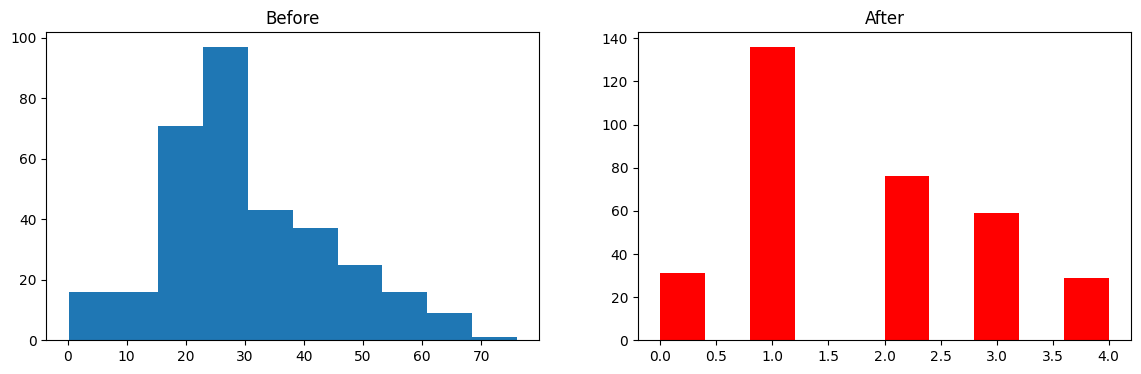

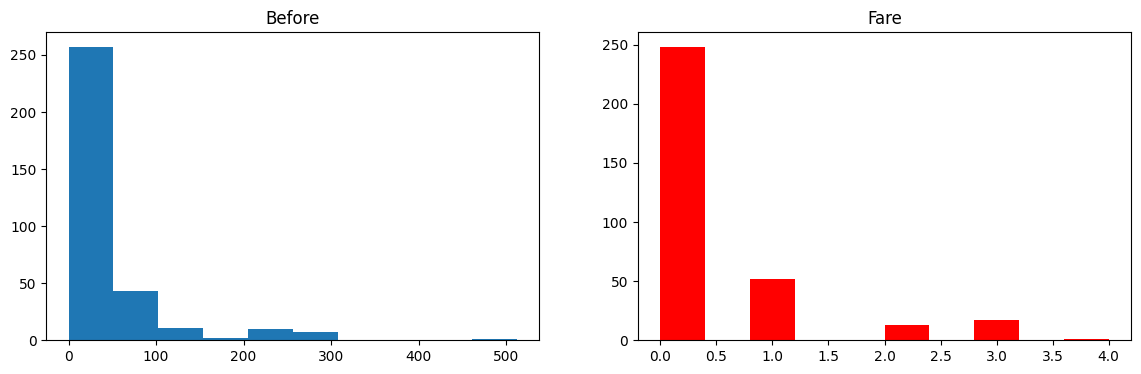

In [69]:
discretize(5,'kmeans')


0.5649732620320854


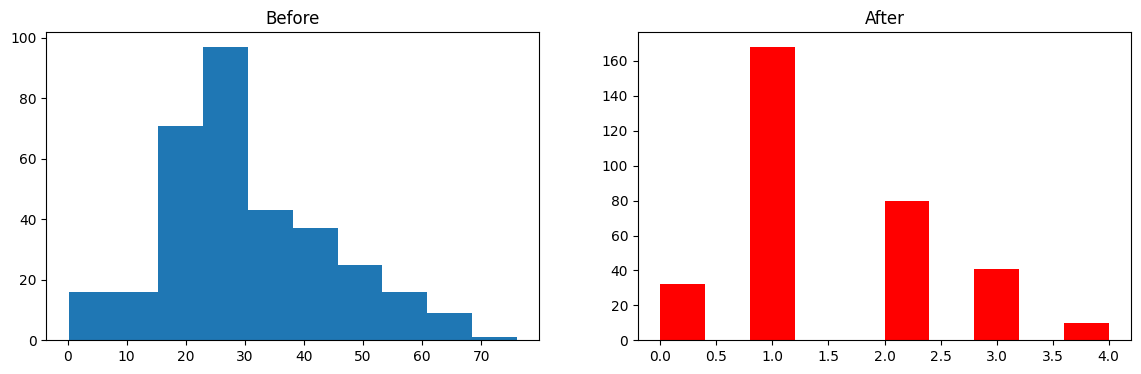

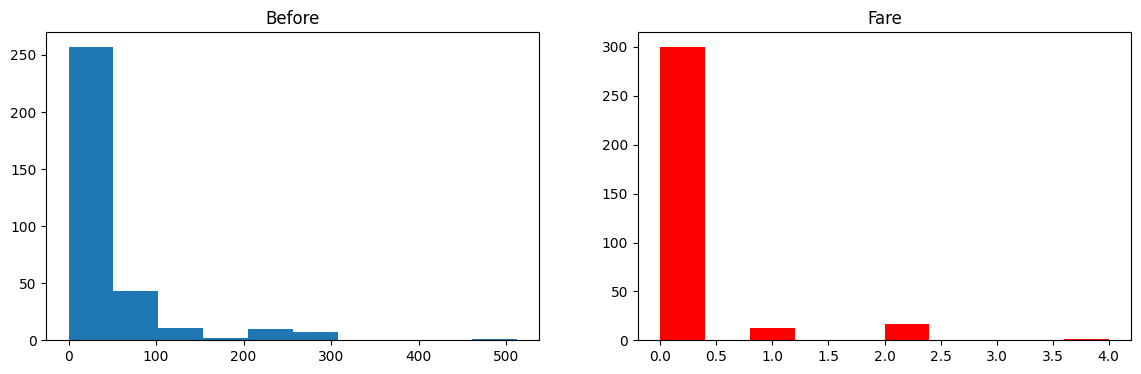

In [70]:
discretize(5,'uniform')


0.5558823529411765


/opt/anaconda3/lib/python3.13/site-packages/sklearn/preprocessing/_discretization.py:296: FutureWarning: The current default behavior, quantile_method='linear', will be changed to quantile_method='averaged_inverted_cdf' in scikit-learn version 1.9 to naturally support sample weight equivalence properties by default. Pass quantile_method='averaged_inverted_cdf' explicitly to silence this warning.
  warnings.warn(
/opt/anaconda3/lib/python3.13/site-packages/sklearn/preprocessing/_discretization.py:296: FutureWarning: The current default behavior, quantile_method='linear', will be changed to quantile_method='averaged_inverted_cdf' in scikit-learn version 1.9 to naturally support sample weight equivalence properties by default. Pass quantile_method='averaged_inverted_cdf' explicitly to silence this warning.
  warnings.warn(


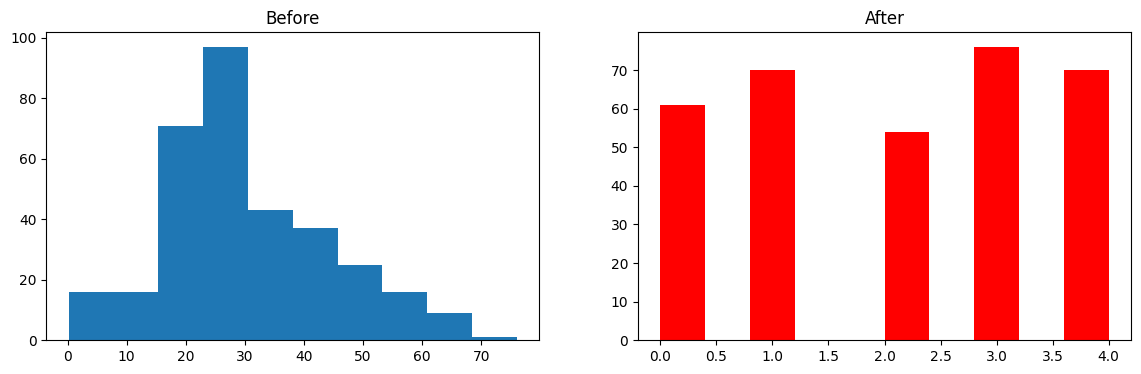

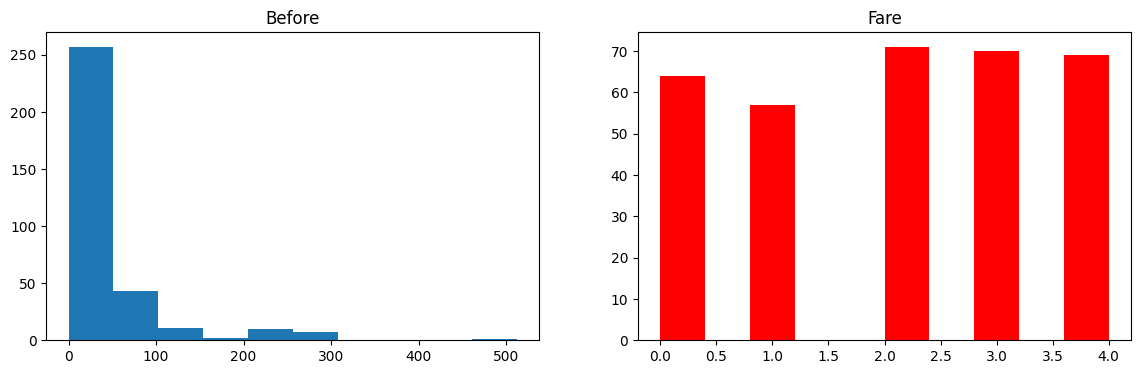

In [71]:
discretize(5,'quantile')


# Binarization 

In [72]:
df=pd.read_csv("../../data/tested.csv",usecols=['Age','Fare','SibSp','Parch','Survived'])

In [73]:
df.dropna(inplace=True)


In [74]:
df.head()

,Survived,Age,SibSp,Parch,Fare
0,0,34.5,0,0,7.8292
1,1,47.0,1,0,7.0000
2,0,62.0,0,0,9.6875
3,0,27.0,0,0,8.6625
4,1,22.0,1,1,12.2875


In [75]:
df['family'] = df['SibSp'] + df['Parch']

In [76]:
df.head()

,Survived,Age,SibSp,Parch,Fare,family
0,0,34.5,0,0,7.8292,0
1,1,47.0,1,0,7.0000,1
2,0,62.0,0,0,9.6875,0
3,0,27.0,0,0,8.6625,0
4,1,22.0,1,1,12.2875,2


In [77]:
df.drop(columns=['SibSp','Parch'],inplace=True)

In [78]:
df.head()

,Survived,Age,Fare,family
0,0,34.5,7.8292,0
1,1,47.0,7.0000,1
2,0,62.0,9.6875,0
3,0,27.0,8.6625,0
4,1,22.0,12.2875,2


In [79]:
X = df.drop(columns=['Survived'])
y = df['Survived']

In [80]:
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42)

In [81]:
X_train.head()

,Age,Fare,family
281,0.75,13.7750,2
96,76.00,78.8500,1
341,32.00,7.5792,0
18,27.00,7.9250,1
26,22.00,61.9792,1


In [82]:
# Without binarization

clf = DecisionTreeClassifier()

clf.fit(X_train,y_train)

y_pred = clf.predict(X_test)

accuracy_score(y_test,y_pred)

0.6119402985074627

In [84]:
np.mean(cross_val_score(DecisionTreeClassifier(),X,y,cv=10,scoring='accuracy'))

np.float64(0.6014260249554368)

# Applying Binarizer

In [85]:
from sklearn.preprocessing import Binarizer

In [86]:
trf = ColumnTransformer([
    ('bin',Binarizer(copy=False),['family'])
],remainder='passthrough')

In [87]:

X_train_trf = trf.fit_transform(X_train)
X_test_trf = trf.transform(X_test)

In [88]:
pd.DataFrame(X_train_trf,columns=['family','Age','Fare'])

,family,Age,Fare
0,1.0,0.75,13.7750
1,1.0,76.00,78.8500
2,0.0,32.00,7.5792
3,1.0,27.00,7.9250
4,1.0,22.00,61.9792
...,...,...,...
259,0.0,20.00,7.2250
260,0.0,27.00,7.8792
261,0.0,43.00,7.8958
262,0.0,16.00,7.6500


In [89]:
clf = DecisionTreeClassifier()
clf.fit(X_train_trf,y_train)
y_pred2 = clf.predict(X_test_trf)

accuracy_score(y_test,y_pred2)

0.6268656716417911

In [90]:
X_trf = trf.fit_transform(X)
np.mean(cross_val_score(DecisionTreeClassifier(),X_trf,y,cv=10,scoring='accuracy'))

np.float64(0.6133689839572192)